# Triagem de anomalias na decolagem (0–250 ft AGL) — EMB 314

Material de apoio prático da Aula 13 (XAI: explicabilidade e confiança).

**Em uma frase, para quem está ouvindo pela primeira vez**: temos milhares de decolagens
gravadas automaticamente, nenhuma delas marcada por um humano como "normal" ou
"problemática" — e vamos pedir ao computador para apontar, sozinho, quais decolagens
parecem diferentes das demais, e depois explicar *por que* ele fez essa escolha, para
que um especialista humano decida o que fazer com essa informação.

**Escopo deste exercício**

- Somente a fase de **decolagem**: da aeronave parada até **250 ft AGL**. Pouso e outras
  frotas ficam fora deste notebook.
- Frota única, dados reais de 1 Hz (519 arquivos de voo, 8 aeronaves anonimizadas).
- Método: PCA + DBSCAN em configuração literal (estilo *ClusterAD-Flight* — Li et al.,
  `[CITATION NEEDED]`) sobre janelas de decolagem vetorizadas, sem qualquer rótulo de
  referência.
- Objetivo pedagógico: mostrar, com dados reais, como (ou se) se sustenta confiança num
  resultado de triagem **sem rótulo** — o eixo central desta aula.

**Fora de escopo aqui** (discussão nos slides): comparação entre frotas e a bateria
completa de robustez (sensibilidade, *bootstrap*, *hold-out* temporal) ficam para
além deste recorte. Os "candidatos" gerados abaixo são **material para revisão
especializada**, com diagnóstico sempre reservado à decisão humana.

## Termos usados neste notebook

Este notebook mistura estatística e engenharia aeronáutica. Para acompanhar sem
precisar decorar as siglas, aqui vai um dicionário rápido — volte a ele sempre que
precisar relembrar um termo. Quem já os conhece pode pular direto para a §1.

- **AGL** ("altura acima do solo"): altura real da aeronave em relação ao chão —
  diferente da altitude bruta do altímetro, que muda com a pressão atmosférica do dia.
- **Vetor / vetorização**: transformar os 71 segundos de um voo — para cada um dos 22
  parâmetros medidos — numa única lista longa de números, para que o computador possa
  comparar "voo A" com "voo B" como se fossem dois pontos num mapa.
- **PCA (Análise de Componentes Principais)**: técnica que resume dezenas de sinais que
  variam juntos (velocidade, temperatura, aceleração...) em um número menor de
  "eixos-resumo". É como reduzir uma foto de altíssima resolução para uma miniatura que
  ainda mostra o essencial da cena.
- **DBSCAN**: método que agrupa pontos parecidos e aponta como "ruído" os pontos que
  ficam isolados — sem que ninguém precise dizer de antemão quantos grupos deveria haver.
- **Cluster**: um grupo de voos parecidos entre si, segundo o DBSCAN.
- **Desvio padronizado / z-score**: quantas "unidades típicas de variação" um valor está
  distante da média da população. z=1 é comum; z=3 já é raro; z=30 (que vamos ver na
  §7) é extremo — é como dizer que algo está 30 vezes mais longe do normal do que o
  habitual.
- **Distância-K / atipicidade**: o quão "sozinho" um voo está em relação aos voos mais
  parecidos com ele, depois de resumidos pelo PCA. Quanto maior, mais incomum é aquele
  voo em relação a todos os outros.
- **MinPts, ε (epsilon), ρ (rho), cv**: parâmetros técnicos do DBSCAN e diagnósticos de
  como esses parâmetros se comportam nestes dados — explicados em linguagem simples onde
  aparecem, na §4.
- **p-valor**: a chance de um resultado tão "diferente" quanto o observado aparecer só
  por acaso, mesmo quando a diferença real é zero. Convenção comum: p < 0,05 é
  considerado um indício provavelmente real, além da coincidência — sempre parcial: uma
  prova definitiva pediria confirmação além de um único teste.
- **Teste de Fisher, Kruskal-Wallis, Mann-Whitney**: três formas diferentes de comparar
  grupos estatisticamente (ex.: "esta aeronave tem mais casos incomuns que as outras?"),
  cada uma adequada a um tipo de dado. A leitura do resultado importa mais do que a
  fórmula — todas produzem um p-valor com a mesma interpretação acima.
- **Parâmetros de motor (`NG`, `NP`, `ITT`, `Q`, `OT`, `OP`...)**: seguem a convenção usual
  de um motor turboélice — `NG` é a rotação do gerador de gases, `NP` a rotação do conjunto
  de potência/hélice (ambas em % do regime nominal), `Q` é o torque, `OT`/`OP` são
  temperatura e pressão do óleo. Aparecem nos resultados da §7 com esses nomes.
- **Correção de Holm**: ajuste aplicado quando se fazem vários testes ao mesmo tempo
  (aqui, um por aeronave) para manter sob controle a chance de "descobrir" diferenças
  falsas só por tentar muitas vezes.
- **Candidato / anomalia**: este notebook trata todo voo sinalizado como hipótese a
  revisar. "Candidato" significa apenas "está no extremo da distribuição, vale a pena um
  especialista olhar" — a decisão final é sempre humana.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler


warnings.filterwarnings("ignore")

DATA_DIR = Path("time_history_1hz_analysis")

BLUE, BLUE_LIGHT, GRAY, INK, CANDIDATE = "#2a78d6", "#b7d3f6", "#898781", "#0b0b0b", "#ec835a"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK,
    "xtick.color": GRAY, "ytick.color": GRAY,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "font.size": 10, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})

## 1. Protocolo de fase: âncora de 250 ft AGL

**Em termos simples**: cada voo começa em um horário diferente e dura um tempo
diferente. Para comparar decolagens de voos distintos, precisamos de um "ponto zero"
comum a todos — como sincronizar vários cronômetros no mesmo instante físico (aqui, o
momento em que a aeronave passa de 250 pés de altura), em vez de usar o relógio da
cabine, que é diferente em cada voo.

A altura vem **somente do altímetro barométrico** (`PALT`) — sem rádio-altímetro, sem
`WOW`. Isso torna o protocolo portátil para qualquer aeronave que tenha altímetro e
velocidade indicada, e evita usar como âncora o mesmo tipo de sinal (altura) que às vezes
é também alvo de investigação.

- **AGL** = `PALT` − elevação de solo, estimada por voo como a mediana de `PALT` no
  trecho lento inicial (`AS` < 40 kt, antes da primeira passagem por 50 kt).
- **Âncora** $A_{250}^{\uparrow}$: primeiro cruzamento **ascendente** de 250 ft AGL que
  sustenta ≥ ~245 ft por **15 s** (evita falso cruzamento por ruído). Debounce de **90 s**
  entre âncoras aceitas, garantindo que cada evento seja contado uma única vez — mas
  **sem** impor uma única decolagem por arquivo: um treinamento pode ter vários circuitos.
- **Janela de decolagem**: **70 s fixos terminando na âncora** — cobre a corrida de
  decolagem (tipicamente ~25 s) e a subida inicial até 250 ft.

In [2]:
GATE_FT = 250.0
SUSTAIN_S = 15
DEBOUNCE_S = 90
SUSTAIN_MARGIN_FT = 5.0
WINDOW_Y_S = 70
LOW_SPEED_KT = 40.0
GROUND_SPLIT_KT = 50.0
MIN_GROUND_SAMPLES = 10
L = WINDOW_Y_S + 1  # amostras por janela (t=-70..0)


def to_num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s, errors="coerce")


def elev_dep(palt: np.ndarray, as_: np.ndarray) -> float | None:
    above = np.where(as_ >= GROUND_SPLIT_KT)[0]
    cut = above[0] if len(above) else len(as_)
    seg = np.zeros(len(as_), dtype=bool)
    seg[:cut] = True
    ground = seg & (as_ < LOW_SPEED_KT) & ~np.isnan(palt)
    if ground.sum() >= MIN_GROUND_SAMPLES:
        return float(np.median(palt[ground]))
    ground_all = (as_ < LOW_SPEED_KT) & ~np.isnan(palt)
    if ground_all.sum() >= MIN_GROUND_SAMPLES:
        return float(np.median(palt[ground_all]))
    return None


def find_takeoff_anchors(sec: np.ndarray, agl: np.ndarray) -> list[int]:
    '''Índices (posição na lista de amostras) dos cruzamentos ascendentes de 250 ft aceitos.'''
    anchors, last_accept_time = [], None
    for i in range(1, len(agl)):
        if agl[i - 1] < GATE_FT <= agl[i]:
            if last_accept_time is None or (sec[i] - last_accept_time) >= DEBOUNCE_S:
                j = min(len(agl), i + SUSTAIN_S + 1)
                if j - i >= SUSTAIN_S and np.all(agl[i:j] >= GATE_FT - SUSTAIN_MARGIN_FT):
                    anchors.append(i)
                    last_accept_time = sec[i]
    return anchors

### Verificação visual num voo real

Antes de rodar em lote, confirmamos a lógica num único voo: a curva de AGL, o portão de
250 ft, a âncora aceita e a janela de 70 s que ela define. Escolhido por uma regra
objetiva e reprodutível — "primeiro arquivo com exatamente uma âncora de decolagem".

Fazemos essa checagem num voo só antes de rodar em milhares porque é muito mais fácil
enxergar um erro de lógica olhando um exemplo concreto do gráfico do que revisando
números agregados de 519 arquivos de uma vez. Se a lógica falhar aqui, ela provavelmente
falha em todos.

exemplo: 20240930_AC01_FC1221.parquet


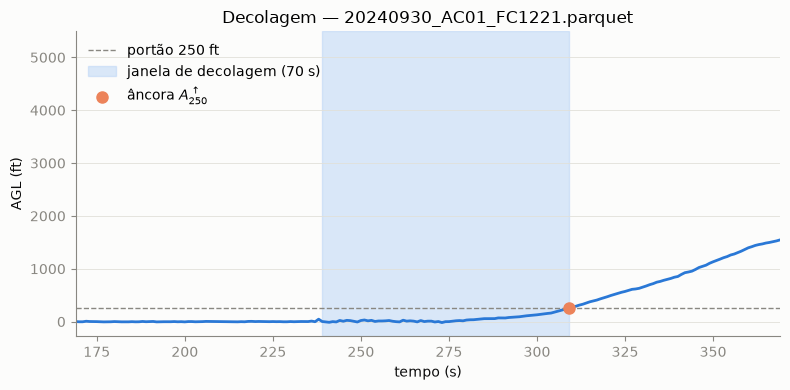

In [3]:
example_fp, example_sec, example_agl, example_anchor = None, None, None, None
for fp in sorted(DATA_DIR.glob("aircraft_tail=*/*.parquet")):
    d = pd.read_parquet(fp, columns=["analysis_second", "PALT", "AS"])
    sec = d["analysis_second"].to_numpy()
    if len(sec) < WINDOW_Y_S + SUSTAIN_S + 5 or not np.all(np.diff(sec) == 1):
        continue
    palt, as_ = to_num(d["PALT"]).to_numpy(), to_num(d["AS"]).to_numpy()
    ed = elev_dep(palt, as_)
    if ed is None:
        continue
    agl = palt - ed
    anchors = find_takeoff_anchors(sec, agl)
    if len(anchors) == 1 and anchors[0] - WINDOW_Y_S >= 0:
        example_fp, example_sec, example_agl, example_anchor = fp, sec, agl, anchors[0]
        break

print("exemplo:", example_fp.name)

fig, ax = plt.subplots(figsize=(8, 4))
t = example_sec - example_sec[0]
ax.plot(t, example_agl, color=BLUE, linewidth=2, solid_capstyle="round")
ax.axhline(GATE_FT, color=GRAY, linestyle="--", linewidth=1, label="portão 250 ft")
t_anchor = t[example_anchor]
ax.axvspan(t_anchor - WINDOW_Y_S, t_anchor, color=BLUE_LIGHT, alpha=0.5, label="janela de decolagem (70 s)")
ax.scatter([t_anchor], [example_agl[example_anchor]], s=64, color=CANDIDATE, zorder=5, label="âncora $A_{250}^{\\uparrow}$")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("AGL (ft)")
ax.set_title(f"Decolagem — {example_fp.name}")
ax.grid(True, axis="y")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(max(0, t_anchor - 140), t_anchor + 60)
plt.tight_layout()
plt.show()

## 2. Inventário de eventos (lote — 519 voos)

Aplicamos a mesma lógica a todos os arquivos ("em lote" = repetir automaticamente, para
os 519 arquivos, exatamente a checagem que acabamos de validar num voo só). Um voo pode
gerar **0, 1 ou vários** eventos de decolagem (circuitos / treinamento); arquivos sem
1 Hz contínuo ou sem trecho de solo suficiente para estimar a elevação são descartes
técnicos.

In [4]:
all_files = sorted(DATA_DIR.glob("aircraft_tail=*/*.parquet"))

CANDIDATE_PARAMS = ["MACH", "ALTR", "APA", "ARA", "APR", "ARR", "AYR", "NX", "NY", "NZ",
                    "NG", "ITT", "Q", "NP", "OT", "OP", "AIL_POS", "ELE_POS", "RUD_POS",
                    "ATP", "ETP", "RTP", "AOA", "FF"]
NO_VALID_FLAG = {"NX", "NY", "NZ", "AIL_POS", "ELE_POS", "RUD_POS"}
LOAD_COLS = ["external_load_detected", "external_load_mass_kg", "external_load_pylon_count"]

_avail = pd.read_parquet(all_files[0]).columns
HAS_FLAG = {p: (p not in NO_VALID_FLAG) for p in CANDIDATE_PARAMS}
VALID_COLS = [p + "_is_valid" for p in CANDIDATE_PARAMS if HAS_FLAG[p]]
READ_COLS = (["analysis_second", "flight_id", "aircraft_tail", "PALT", "AS", "MAG_HDG",
              "MAG_HDG_is_valid"] + CANDIDATE_PARAMS + VALID_COLS + LOAD_COLS)


def read_flight(fp: Path) -> pd.DataFrame | None:
    df = pd.read_parquet(fp, columns=READ_COLS)
    sec = df["analysis_second"].to_numpy()
    if len(sec) < WINDOW_Y_S + SUSTAIN_S + 5 or not np.all(np.diff(sec) == 1):
        return None
    for c in ["PALT", "AS", "MAG_HDG"] + CANDIDATE_PARAMS:
        df[c] = to_num(df[c])
    return df


def extract_window(df: pd.DataFrame, anchor_pos: int) -> dict | None:
    start = anchor_pos - WINDOW_Y_S
    if start < 0:
        return None
    win = df.iloc[start: anchor_pos + 1].reset_index(drop=True)
    if len(win) != L:
        return None
    load_mass = df["external_load_mass_kg"].iloc[0]
    return {"df": win, "flight_id": df["flight_id"].iloc[0], "tail": df["aircraft_tail"].iloc[0],
            "anchor_second": int(df["analysis_second"].iloc[anchor_pos]),
            "external_load": bool(df["external_load_detected"].fillna(False).iloc[0]),
            "external_load_mass_kg": float(load_mass) if pd.notna(load_mass) else np.nan}


windows, n_flights_used, n_flights_skipped, n_anchors_total = [], 0, 0, 0
for fp in all_files:
    df = read_flight(fp)
    if df is None:
        n_flights_skipped += 1
        continue
    ed = elev_dep(df["PALT"].to_numpy(), df["AS"].to_numpy())
    if ed is None:
        n_flights_skipped += 1
        continue
    agl = df["PALT"].to_numpy() - ed
    anchors = find_takeoff_anchors(df["analysis_second"].to_numpy(), agl)
    n_anchors_total += len(anchors)
    n_flights_used += 1 if anchors else 0
    for pos in anchors:
        w = extract_window(df, pos)
        if w is not None:
            windows.append(w)

print(f"arquivos: {len(all_files)} | com >=1 âncora: {n_flights_used} | "
      f"descartes técnicos: {n_flights_skipped}")
print(f"âncoras (eventos de decolagem): {n_anchors_total} | "
      f"janelas com cobertura completa de 70 s: {len(windows)}")

arquivos: 519 | com >=1 âncora: 403 | descartes técnicos: 20
âncoras (eventos de decolagem): 1011 | janelas com cobertura completa de 70 s: 1011


## 3. Seleção de *features* e vetorização

**Em termos simples**: um "parâmetro" (ou *feature*) é qualquer grandeza medida durante
o voo — velocidade, temperatura do motor, ângulo de inclinação etc. Nem todo parâmetro
medido entra na comparação: alguns ficam de fora por decisão de projeto (explicado
abaixo); outros porque, na prática, carregam a mesma informação que um parâmetro já
incluído (redundância); e um problema real de sensor (a "sentinela", abaixo) precisou
ser corrigido antes de qualquer conta, senão distorceria o resultado.

Cada janela (71 amostras × parâmetro) é achatada num vetor `<parâmetro>__t000 ... t070`
(uma população dedicada só à decolagem, separada do pouso). Antes disso:

- **Confundidores e circularidade excluídos por decisão de projeto** — um critério de
  engenharia, aplicado antes de qualquer cálculo estatístico: altitude bruta
  (`PALT`/`RAD_ALT` — é a própria variável da janela), velocidade indicada `AS`
  (inválida por projeto na corrida — abriria um vão estrutural > 5 s bem no início de
  toda janela), temperatura ambiente `T1`, posição (`GPSLAT/GPSLONG`), manete de
  potência `PCL` (comando do piloto — circular com a própria manobra), rumo bruto
  `MAG_HDG` (só entra como variação relativa ao início da janela, invariante à pista).
- **Sentinela de saturação**: alguns parâmetros de aceleração saturam num valor exato,
  extremo e frequente — a assinatura de uma falha de sensor disfarçada de medição
  (imagine um sensor que, ao falhar numa leitura, devolve sempre o mesmo número
  customizado em vez de sinalizar a falha) — detectamos e mascaramos antes de qualquer
  estatística, senão ele infla correlações de forma espúria.
- **Validade insuficiente** (< 90% de amostras válidas no conjunto de janelas): descarta
  o parâmetro.
- **Redundância** (|correlação| ≥ 0,95 com outro parâmetro já selecionado): descarta o
  redundante.

In [5]:
# Procura um valor "grudado" (sentinela) que aparece demais e destoa do resto -- assinatura de sensor travado, distinta da fisica real.
def detect_sentinel(values: np.ndarray) -> float | None:
    '''Valor no extremo (mín. ou máx.), com share >= 2% e a mais de 5x o IQR do resto
    da distribuição: indício de saturação/preenchimento do sensor, distinto de um
    extremo físico genuíno.'''
    v = values[~np.isnan(values)]
    if len(v) == 0:
        return None
    for candidate in (v.min(), v.max()):
        share = np.mean(v == candidate)
        if share < 0.02:
            continue
        rest = v[v != candidate]
        if len(rest) < 10:
            continue
        med = np.median(rest)
        q75, q25 = np.percentile(rest, [75, 25])
        iqr = q75 - q25
        if iqr > 0 and abs(candidate - med) > 5 * iqr:
            return float(candidate)
    return None


def max_run(mask: np.ndarray) -> int:
    best = cur = 0
    for m in mask:
        cur = cur + 1 if m else 0
        best = max(best, cur)
    return best


N_WIN = len(windows)
raw = {p: np.full((N_WIN, L), np.nan) for p in CANDIDATE_PARAMS}
valid = {p: np.zeros((N_WIN, L), dtype=bool) for p in CANDIDATE_PARAMS}

for wi, w in enumerate(windows):
    d = w["df"]
    for p in CANDIDATE_PARAMS:
        vals = d[p].to_numpy(dtype=float)
        raw[p][wi] = vals
        if HAS_FLAG[p]:
            valid[p][wi] = (d[p + "_is_valid"].to_numpy() == True) & ~np.isnan(vals)  # noqa: E712
        else:
            valid[p][wi] = ~np.isnan(vals)

sentinels = {}
for p in CANDIDATE_PARAMS:
    sv = detect_sentinel(raw[p][valid[p]])
    if sv is not None:
        sentinels[p] = sv
        hit = np.isclose(raw[p], sv)
        valid[p][hit] = False
        raw[p][hit] = np.nan

print("sentinelas detectadas:", sentinels)

pooled_validity = {p: valid[p].mean() for p in CANDIDATE_PARAMS}
survivors = [p for p in CANDIDATE_PARAMS if pooled_validity[p] >= 0.90]
print("descartados por validade < 90%:",
      {p: f"{pooled_validity[p]:.1%}" for p in CANDIDATE_PARAMS if p not in survivors})

flat = {p: raw[p].reshape(-1) for p in survivors}
flat_valid = {p: valid[p].reshape(-1) for p in survivors}
dropped_corr = []
for a_i, a in enumerate(survivors):
    if a in dropped_corr:
        continue
    for b in survivors[a_i + 1:]:
        if b in dropped_corr:
            continue
        m = flat_valid[a] & flat_valid[b]
        if m.sum() < 100:
            continue
        r = np.corrcoef(flat[a][m], flat[b][m])[0, 1]
        if abs(r) >= 0.95:
            print(f"descartado por redundância: {b} (r={r:.3f} com {a})")
            dropped_corr.append(b)

selected = [p for p in survivors if p not in dropped_corr]
print(f"\nfeatures selecionadas ({len(selected)} + variação de rumo):", selected)

sentinelas detectadas: {'NX': -5.42, 'NY': -2.17, 'NZ': -5.63}
descartados por validade < 90%: {'AOA': '84.2%'}


descartado por redundância: FF (r=0.986 com Q)

features selecionadas (22 + variação de rumo): ['MACH', 'ALTR', 'APA', 'ARA', 'APR', 'ARR', 'AYR', 'NX', 'NY', 'NZ', 'NG', 'ITT', 'Q', 'NP', 'OT', 'OP', 'AIL_POS', 'ELE_POS', 'RUD_POS', 'ATP', 'ETP', 'RTP']


In [6]:
def heading_delta(hdg: np.ndarray) -> np.ndarray:
    unwrapped = np.rad2deg(np.unwrap(np.deg2rad(hdg)))
    return unwrapped - unwrapped[0]


kept = []
for w in windows:
    d = w["df"]
    series, ok = {}, True
    for p in selected:
        vals = d[p].to_numpy(dtype=float).copy()
        if p in sentinels:
            vals[np.isclose(vals, sentinels[p])] = np.nan
        if HAS_FLAG[p]:
            vals[d[p + "_is_valid"].to_numpy() != True] = np.nan  # noqa: E712
        invalid = np.isnan(vals)
        if (1 - invalid.mean()) < 0.90 or max_run(invalid) > 5:
            ok = False
            break
        if invalid.any():
            idx = np.arange(L)
            vals = np.interp(idx, idx[~invalid], vals[~invalid])
        series[p] = vals
    if not ok:
        continue
    hdg = d["MAG_HDG"].to_numpy(dtype=float).copy()
    hdg[d["MAG_HDG_is_valid"].to_numpy() != True] = np.nan  # noqa: E712
    inv = np.isnan(hdg)
    if inv.all():
        continue
    if inv.any():
        idx = np.arange(L)
        hdg = np.interp(idx, idx[~inv], hdg[~inv])
    vec = np.concatenate([series[p] for p in selected] + [heading_delta(hdg)])
    kept.append({"flight_id": w["flight_id"], "tail": w["tail"], "anchor_second": w["anchor_second"],
                 "external_load": w["external_load"], "external_load_mass_kg": w["external_load_mass_kg"],
                 "vector": vec})

X = np.vstack([k["vector"] for k in kept])
meta = pd.DataFrame([{k: v for k, v in kw.items() if k != "vector"} for kw in kept])
print(f"janelas após filtro de cobertura por janela: {len(kept)} / {len(windows)}")
print("dimensão da matriz de instâncias X:", X.shape)

janelas após filtro de cobertura por janela: 928 / 1011
dimensão da matriz de instâncias X: (928, 1633)


## 4. Detecção literal: PCA (90% de variância) + DBSCAN

**Em termos simples**: o PCA resume os 1633 números de cada janela de voo em um punhado
de "eixos-resumo" que capturam a maior parte da variação entre os voos (a receita
literal aqui exige que esses eixos expliquem 90% dessa variação). O DBSCAN então olha a
posição de cada voo nesse espaço resumido e decide: este voo tem vizinhos parecidos por
perto (faz parte de um grupo, ou *cluster*) ou está sozinho, longe de todo mundo (é
"ruído" — candidato a revisão)?

Configuração literal (Li et al., `[CITATION NEEDED]`): padronizar cada coluna do vetor
(z-score), reter componentes principais até 90% de variância acumulada (**K**), rodar
DBSCAN nesse espaço de K dimensões com $\mathrm{MinPts} = K+1$. O raio $\varepsilon$ é
lido **diretamente** do percentil da distância-K, para três alvos de ruído (1%, 5%,
10%) — sem otimizar para acertar a fração nominal: a diferença entre alvo e resultado
real já é, em si, informação de diagnóstico (ver §5).

In [7]:
# 1) padroniza cada coluna (media 0, desvio 1) -- necessario porque os parametros tem escalas muito diferentes (kt, graus, psi...)
Xs = StandardScaler().fit_transform(X)
pca = PCA(svd_solver="full").fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
K = int(np.searchsorted(cum, 0.90) + 1)
scores = pca.transform(Xs)[:, :K]
min_samples = K + 1

# distancia de cada voo ao seu vizinho mais proximo "MinPts" -- essa distancia e a nossa medida de atipicidade
nn = NearestNeighbors(n_neighbors=min_samples).fit(scores)
dist, _ = nn.kneighbors(scores)
kd = np.sort(dist[:, -1])

rho = min_samples / X.shape[0]
cv_kdist = kd.std() / kd.mean()
print(f"n={X.shape[0]}  dim={X.shape[1]}  K={K} (var. acumulada {cum[K-1]:.1%})  "
      f"MinPts={min_samples}")
print(f"rho = MinPts/n = {rho:.3f}   cv(distância-K) = {cv_kdist:.3f}")

results = {}
for target in (0.01, 0.05, 0.10):
    eps = np.percentile(kd, 100 * (1 - target))
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(scores)
    n_noise = int((labels == -1).sum())
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    results[target] = {"eps": eps, "labels": labels, "n_noise": n_noise, "n_clusters": n_clusters}
    print(f"  alvo {target:.0%}: eps={eps:6.2f}  ruído real={n_noise/len(labels):5.1%} "
          f"({n_noise:3d} janelas)  clusters={n_clusters}")

n=928  dim=1633  K=101 (var. acumulada 90.1%)  MinPts=102
rho = MinPts/n = 0.110   cv(distância-K) = 0.354
  alvo 1%: eps= 74.68  ruído real= 0.2% (  2 janelas)  clusters=1
  alvo 5%: eps= 62.75  ruído real= 1.7% ( 16 janelas)  clusters=1
  alvo 10%: eps= 53.17  ruído real= 4.6% ( 43 janelas)  clusters=1


### Lendo $\rho$ e o coeficiente de variação da distância-K

**Em uma frase**: os dois números abaixo ($\rho$ e cv) dizem se está fácil ou difícil
para o DBSCAN separar grupos distintos nestes dados — aqui, como veremos, está difícil,
e isso tem uma explicação matemática, um comportamento esperado do método diante da
geometria destes dados.

$\rho = \mathrm{MinPts}/n$ próximo de 0,10 já é alto: a regra literal de vizinhança está
exigindo cerca de 10% da população inteira como vizinhança mínima de um cluster — em
$n$ pequeno, isso satura rápido. O **cv da distância-K** mede o quão concentradas estão
essas distâncias: quando é baixo, quase todo ponto tem a mesma distância ao seu
K-ésimo vizinho, e o DBSCAN tende a enxergar **um único cluster** (a densidade parece
uniforme) mesmo quando ainda sobram candidatos no extremo da distribuição a um alvo de
ruído fixo. É exatamente esse padrão — colapso estrutural (poucos ou nenhum cluster
além do principal) coexistindo com candidatos substanciais a 5% — que este notebook
deveria reproduzir abaixo. Isso é uma propriedade esperada do método, e é exatamente a
razão pela qual a **pontuação de atipicidade** (distância-K) é a grandeza que se deve
reportar com confiança, mais do que o rótulo binário de cluster — o corte contingente é
o alvo de ruído escolhido, a ordenação é mais estável (ver discussão em §8).

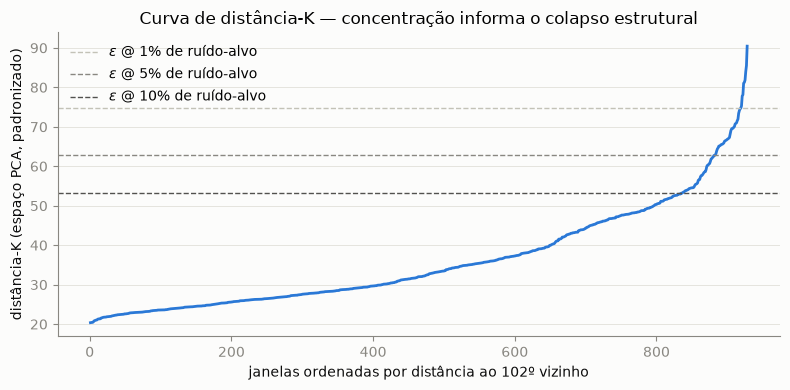

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(kd) + 1), kd, color=BLUE, linewidth=2)
palette_by_target = {0.01: "#c3c2b7", 0.05: "#898781", 0.10: "#52514e"}
for target, res in results.items():
    ax.axhline(res["eps"], color=palette_by_target[target], linestyle="--", linewidth=1,
               label=f"$\\varepsilon$ @ {target:.0%} de ruído-alvo")
ax.set_xlabel(f"janelas ordenadas por distância ao {min_samples}º vizinho")
ax.set_ylabel("distância-K (espaço PCA, padronizado)")
ax.set_title("Curva de distância-K — concentração informa o colapso estrutural")
ax.grid(True, axis="y")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 5. Candidatos para revisão especializada (alvo de ruído = 5%)

Os pontos sinalizados abaixo são **candidatos a revisão** — o extremo da distribuição de
atipicidade nesta população específica (decolagens do EMB 314, 0–250 ft), sob esta
configuração literal de PCA+DBSCAN. Servem como lista de priorização para revisão
especializada; a etapa de diagnóstico continua sendo humana. Pense nesta lista como um
"top 16" de decolagens mais fora do padrão entre 928, candidatas a uma segunda olhada.

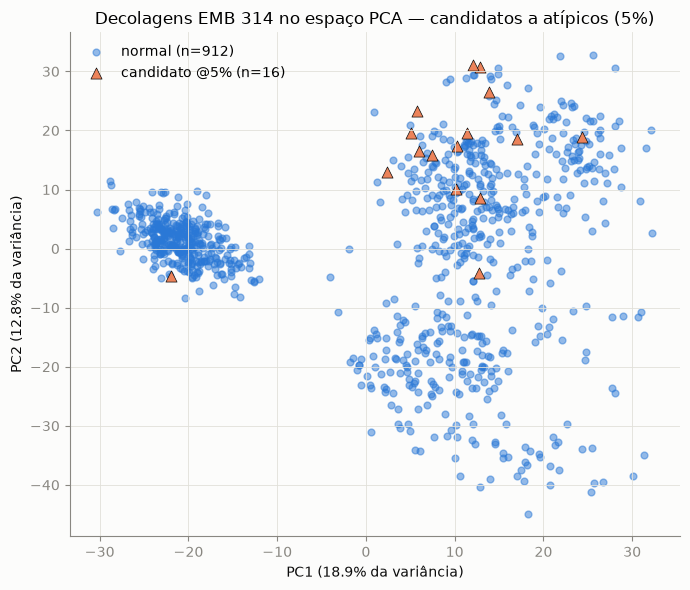

,flight_id,tail,anchor_second,atypicality_kdist
0,20250630_AC01_FC1310,AC01,1143,90.438045
1,20250415_AC03_FC6782,AC03,5473,85.522997
2,20241219_AC03_FC6727,AC03,4360,83.985353
3,20241007_AC01_FC1231,AC01,4648,81.835044
4,20250828_AC06_FC0641,AC06,6210,81.237319
5,20250828_AC06_FC0641,AC06,5797,81.065823
6,20000818_AC05_FC0964,AC05,3549,78.128391
7,20250522_AC06_FC0573,AC06,5476,77.797962
8,20250407_AC08_FC0366,AC08,3551,75.298173
9,20250516_AC03_FC6826,AC03,6186,74.724218


In [9]:
target = 0.05
labels5 = results[target]["labels"]
meta["atypicality_kdist"] = kd_scores = dist[:, -1]
meta["candidate_5pct"] = labels5 == -1

fig, ax = plt.subplots(figsize=(7, 6))
normal = ~meta["candidate_5pct"]
ax.scatter(scores[normal, 0], scores[normal, 1], s=24, color=BLUE, alpha=0.5,
           label=f"normal (n={normal.sum()})")
ax.scatter(scores[~normal, 0], scores[~normal, 1], s=64, color=CANDIDATE, marker="^",
           edgecolor=INK, linewidth=0.5, label=f"candidato @5% (n={(~normal).sum()})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} da variância)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} da variância)")
ax.set_title("Decolagens EMB 314 no espaço PCA — candidatos a atípicos (5%)")
ax.grid(True)
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

cols = ["flight_id", "tail", "anchor_second", "atypicality_kdist"]
(meta.loc[meta["candidate_5pct"], cols]
     .sort_values("atypicality_kdist", ascending=False)
     .reset_index(drop=True))

## 6. Concentração dos candidatos: aeronave (e piloto, se disponível)

**Pergunta em linguagem simples**: os voos "fora do padrão" que encontramos na §5 são
de aeronaves diferentes, espalhados ao acaso, ou concentrados sempre na(s) mesma(s)
aeronave(s)? Se concentrados, isso é um sinal a mais para investigar; se espalhados, é
menos preocupante.

Como só há 1 cluster além do ruído (§4), "cluster" aqui forma um bloco único — a
pergunta útil vira: **os candidatos (ou, de forma mais robusta, a pontuação contínua de
atipicidade) se concentram nalguma aeronave mais do que o acaso sugeriria?** Duas
hipóteses de leitura distintas para essa concentração, caso ela apareça:

- concentrada numa **aeronave** → hipótese de causa material/estrutural, a cruzar com o
  histórico de manutenção dessa cauda;
- concentrada num **piloto** → hipótese de treinamento, a cruzar com o histórico de
  instrução — mas **os dados de voo usados aqui carecem de identificador de piloto**
  (uma lacuna que confirmamos abaixo por busca de coluna, com evidência direta). A
  função definida a seguir já serve para essa análise, bastando um `merge` de `meta`
  com uma escala de tripulação por `flight_id`/data do voo quando essa informação
  existir.

**Leitura obrigatória antes de qualquer conclusão causal**: a atribuição de cauda segue
critérios operacionais — esquadrilhas, base, papel na frota (treinamento de solo vs.
voo com instrutor) — que podem correlacionar com a aeronave sem que a aeronave seja a
causa. O mesmo vale para piloto (nível de experiência, tipo de missão designada).
Concentração estatística aqui é **gatilho para investigação dirigida** — a confirmação
exige evidência adicional, como o histórico de manutenção.

In [10]:
possible_crew_cols = [c for c in pd.read_parquet(all_files[0]).columns
                      if any(k in c.upper() for k in
                             ["PILOT", "CREW", "PIC", "OPERATOR", "INSTRUCTOR", "ALUNO",
                              "STUDENT", "TRIPULA"])]
print("colunas de identificação de tripulação encontradas nos dados de voo:",
      possible_crew_cols or "nenhuma")

colunas de identificação de tripulação encontradas nos dados de voo: nenhuma


In [11]:
from scipy import stats
from statsmodels.stats.multitest import multipletests


def candidate_concentration_by(meta_df, group_col, candidate_col="candidate_5pct",
                                score_col="atypicality_kdist"):
    '''Para cada grupo (ex.: aeronave, piloto): taxa de candidatos, teste exato de Fisher
    (unilateral, grupo vs. resto, na direção de excesso) e mediana da pontuação
    contínua de atipicidade. p-valores corrigidos por Holm (comparações múltiplas).'''
    n_total, k_total = len(meta_df), int(meta_df[candidate_col].sum())
    rows = []
    for g, sub in meta_df.groupby(group_col):
        n_g, k_g = len(sub), int(sub[candidate_col].sum())
        rest_n, rest_k = n_total - n_g, k_total - k_g
        table = [[k_g, n_g - k_g], [rest_k, rest_n - rest_k]]
        _, p = stats.fisher_exact(table, alternative="greater")
        rows.append({group_col: g, "n": n_g, "candidatos": k_g, "taxa": k_g / n_g,
                     "score_mediano": sub[score_col].median(), "p_fisher": p})
    out = pd.DataFrame(rows).sort_values(group_col).reset_index(drop=True)
    out["p_holm"] = multipletests(out["p_fisher"], method="holm")[1]
    return out.sort_values("p_fisher").reset_index(drop=True)


by_tail = candidate_concentration_by(meta, "tail")
by_tail["taxa"] = by_tail["taxa"].map(lambda x: f"{x:.1%}")
by_tail["p_fisher"] = by_tail["p_fisher"].map(lambda x: f"{x:.3f}")
by_tail["p_holm"] = by_tail["p_holm"].map(lambda x: f"{x:.3f}")
print(f"taxa de candidatos na população inteira: {meta['candidate_5pct'].mean():.1%} "
      f"({int(meta['candidate_5pct'].sum())}/{len(meta)})")
by_tail

taxa de candidatos na população inteira: 1.7% (16/928)


,tail,n,candidatos,taxa,score_mediano,p_fisher,p_holm
0,AC03,168,5,3.0%,32.895335,0.147,1.000
1,AC01,121,3,2.5%,29.742375,0.348,1.000
2,AC06,234,5,2.1%,34.124482,0.377,1.000
3,AC08,148,2,1.4%,32.942010,0.752,1.000
4,AC05,146,1,0.7%,31.208939,0.937,1.000
5,AC04,27,0,0.0%,29.394063,1.000,1.000
6,AC07,84,0,0.0%,29.772145,1.000,1.000


**Em termos simples, "poder estatístico baixo" quer dizer**: com poucos exemplos (aqui,
só 16 candidatos espalhados por 8 aeronaves), é difícil provar estatisticamente uma
diferença real mesmo que ela exista de fato — ausência de prova é diferente de prova de
ausência.

Com 16 candidatos distribuídos por 8 aeronaves (2 por cauda em média sob H0), o teste
por cauda tem **potência baixa** — um `p_holm` alto aqui é compatível tanto com
ausência de efeito quanto com um efeito real que este $n$ é pequeno demais para
detectar com confiança. Por isso complementamos com um teste de omissão sobre a
pontuação **contínua**, que aproveita as 928 janelas inteiras da amostra, além dos 16
candidatos isolados:

Kruskal-Wallis (atipicidade ~ aeronave): H=13.40  p=0.037


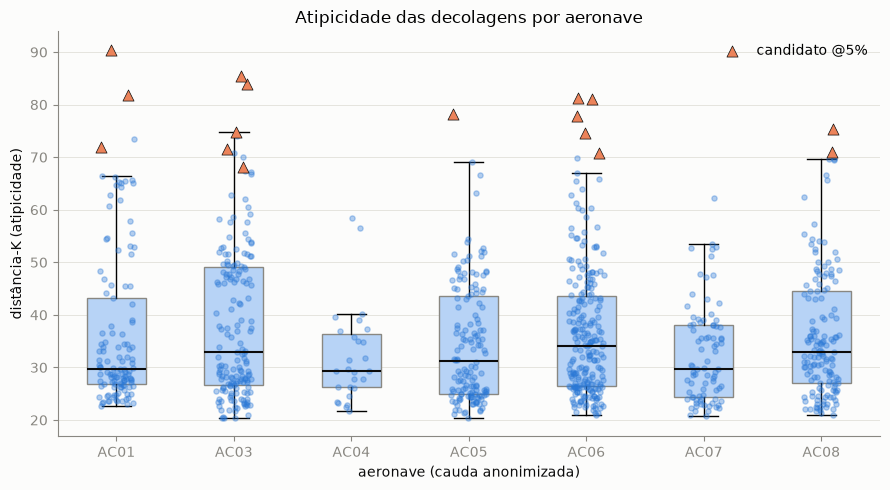

In [12]:
groups = [sub["atypicality_kdist"].to_numpy() for _, sub in meta.groupby("tail")]
h_stat, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis (atipicidade ~ aeronave): H={h_stat:.2f}  p={p_kw:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
tails_sorted = sorted(meta["tail"].unique())
data_by_tail = [meta.loc[meta["tail"] == t, "atypicality_kdist"].to_numpy() for t in tails_sorted]
bp = ax.boxplot(data_by_tail, positions=range(len(tails_sorted)), widths=0.5,
                 showfliers=False, patch_artist=True)
for box in bp["boxes"]:
    box.set(facecolor=BLUE_LIGHT, edgecolor=GRAY, linewidth=1)
for med in bp["medians"]:
    med.set(color=INK, linewidth=1.5)

rng = np.random.default_rng(0)
labeled = False
for i, t in enumerate(tails_sorted):
    sub = meta[meta["tail"] == t]
    normal, cand = sub[~sub["candidate_5pct"]], sub[sub["candidate_5pct"]]
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(normal)), normal["atypicality_kdist"],
               s=14, color=BLUE, alpha=0.35, zorder=2)
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(cand)), cand["atypicality_kdist"],
               s=64, color=CANDIDATE, marker="^", edgecolor=INK, linewidth=0.5, zorder=3,
               label=None if labeled or len(cand) == 0 else "candidato @5%")
    labeled = labeled or len(cand) > 0

ax.set_xticks(range(len(tails_sorted)))
ax.set_xticklabels(tails_sorted)
ax.set_xlabel("aeronave (cauda anonimizada)")
ax.set_ylabel("distância-K (atipicidade)")
ax.set_title("Atipicidade das decolagens por aeronave")
ax.grid(True, axis="y")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

### Leitura do resultado

O teste de Fisher por aeronave, individualmente, perde significância após a correção de
Holm — esperado, já que há só 16 candidatos para dividir entre 8 caudas (potência
baixa: sob H0, ~2 por cauda). Mas o teste de Kruskal-Wallis sobre a pontuação
**contínua** de atipicidade — que aproveita as 928 janelas inteiras, além dos 16
candidatos — indica diferença global entre aeronaves (H=13,40; p=0,037, ou seja: uma
diferença deste tamanho apareceria por puro acaso em menos de 4 vezes a cada 100
tentativas). Isso é evidência de que a pontuação contínua carrega mais informação
estatística do que o corte binário, exatamente o ponto já levantado em §4: aqui o corte
@5% ficou "cego" para um sinal que a ordenação completa capta.

Descritivamente, **AC03** e **AC06** concentram a maior contagem de candidatos (5 cada
uma, sobre 168 e 234 janelas) e a maior mediana de atipicidade; **AC04** e **AC07**
ficam com zero candidatos e a mediana mais baixa — mas AC04 tem só 27 janelas, o que já
limita qualquer leitura sobre essa cauda especificamente. O resultado é gatilho para
checar o histórico de manutenção de AC03 e AC06 no período coberto por estes voos — a
confirmação de problema estrutural exige antes descartar explicações mais simples:
missão típica, esquadrilha ou período de calendário cobertos por cada cauda, tanto
quanto a própria aeronave.

### Um confundidor concreto: carga externa (pilões)

**"Confundidor", em termos simples**: uma causa alternativa e mais simples, que pode
explicar o mesmo resultado sem que haja nada de errado com a aeronave. Antes de suspeitar
de defeito, vale eliminar as explicações mais baratas de checar — como fazemos abaixo.

Antes de investigar manutenção, vale descartar uma explicação mais simples e já presente
nos dados: **tipo de decolagem**. Os arquivos trazem indicadores de carga externa por
sortida (`external_load_detected`, `external_load_mass_kg`, `external_load_pylon_count`)
— constantes ao longo de cada voo, ou seja, descrevem a configuração fixa da sortida, do
início ao fim. Uma decolagem com carga é fisicamente distinta (mais peso, corrida mais
longa, atitude de rotação diferente): se AC03/AC06 realizam mais sortidas carregadas do
que as demais caudas, isso explicaria boa parte da concentração observada acima sem
exigir nenhuma hipótese de defeito.

In [13]:
load_rate_overall = meta["external_load"].mean()
print(f"incidência de carga externa nas janelas de decolagem: {load_rate_overall:.1%} "
      f"({int(meta['external_load'].sum())}/{len(meta)})")

by_tail_load = (meta.groupby("tail")["external_load"].mean().sort_values(ascending=False) * 100).round(1)
print("\ncarga externa por aeronave (%):")
print(by_tail_load.astype(str) + "%")

table = pd.crosstab(meta["external_load"], meta["candidate_5pct"])
_, p_load = stats.fisher_exact(table, alternative="greater")
print(f"\ncarga externa x candidato @5% (Fisher, unilateral, carga -> mais candidato): "
      f"p={p_load:.3f}")
print(table.rename(index={False: "sem carga", True: "com carga"},
                    columns={False: "normal", True: "candidato@5%"}))

no_load = meta[~meta["external_load"]]
groups_no_load = [sub["atypicality_kdist"].to_numpy() for _, sub in no_load.groupby("tail") if len(sub) > 1]
h2, p2 = stats.kruskal(*groups_no_load)
print(f"\nKruskal-Wallis (atipicidade ~ aeronave), só janelas SEM carga externa "
      f"(n={len(no_load)}): H={h2:.2f}  p={p2:.3f}")

incidência de carga externa nas janelas de decolagem: 0.9% (8/928)

carga externa por aeronave (%):
tail
AC06    2.1%
AC05    2.1%
AC01    0.0%
AC04    0.0%
AC03    0.0%
AC07    0.0%
AC08    0.0%
Name: external_load, dtype: str

carga externa x candidato @5% (Fisher, unilateral, carga -> mais candidato): p=1.000
candidate_5pct  normal  candidato@5%
external_load                       
sem carga          904            16
com carga            8             0

Kruskal-Wallis (atipicidade ~ aeronave), só janelas SEM carga externa (n=920): H=13.69  p=0.033


**Leitura**: a hipótese de carga externa fica **descartada** para este efeito. A
incidência é baixíssima no geral (0,9%, 8/928) e **AC03 — a cauda com mais candidatos —
apresenta 0,0% de incidência de carga externa neste recorte**; só AC05 e AC06 têm alguma incidência
(2,1% cada), longe de bastar como explicação. O teste de Fisher carga×candidato aponta
independência entre as duas variáveis (p=1,000 — nenhuma das 8 janelas com carga virou
candidata) e o Kruskal-Wallis restrito às 920 janelas **sem** carga mantém a diferença
entre aeronaves praticamente inalterada (H=13,69; p=0,033, contra H=13,40; p=0,037 na
amostra completa).

Carga externa fica descartada, portanto, como o confundidor que explicaria AC03/AC06 —
o gatilho para checar o histórico de manutenção dessas duas caudas continua de pé. Isto
reforça o gatilho de investigação sem fechar o caso: outros confundidores possíveis
(esquadrilha, base, período) continuam por testar antes de qualquer conclusão sobre
causa estrutural — mas a hipótese de tipo de decolagem por carga, a mais barata de
descartar com os dados já disponíveis, já está fora de cogitação.

## 7. Explicação local de um candidato: quais parâmetros pesam mais?

**Em termos simples**: até aqui, sabemos QUE um voo é incomum (um número: a
distância-K), mas ainda falta saber POR QUÊ. Esta seção tenta responder "por quê",
apontando quais dos 22 parâmetros medidos mais contribuem para esse voo parecer
estranho — a parte do notebook mais parecida com o que SHAP/LIME fazem no Tempo 1, mas
construída na mão, já que este método foi desenhado para detectar, e a explicação fica
por nossa conta.

O PCA+DBSCAN classifica a janela inteira (1633 dimensões) de uma só vez, como um
veredito único — cabe a nós descobrir qual parte do voo motivou esse veredito. Isso é
um problema diferente do que SHAP/LIME resolvem (Tempo 1): lá existe um modelo com
rótulo e uma predição pontual a explicar; aqui existe apenas uma distância num espaço
reduzido, sem predição nem rótulo de referência. Ainda assim, dá para montar um
diagnóstico interpretável sobre *o que*, fisicamente, torna esta janela atípica: o
desvio padronizado (z-score) de cada parâmetro ao longo da janela, em relação à
população de 928 decolagens.

**Isto é um diagnóstico complementar e interpretável**, mais simples do que uma
decomposição matemática formal da distância-K (calculada no espaço de componentes
principais) — no espírito dos *drivers* que a literatura de ClusterAD-Flight já
reporta: qual parâmetro mais se afasta do padrão da frota nesta janela específica.

In [14]:
# vamos comparar o voo mais atipico com todos os outros, parametro por parametro
FEATURE_ORDER = selected + ["HDG_DELTA_FROM_START"]
top_idx = meta.loc[meta["candidate_5pct"], "atypicality_kdist"].idxmax()
top = meta.loc[top_idx]
print(f"candidato mais atípico: {top['flight_id']} ({top['tail']}), "
      f"score={top['atypicality_kdist']:.1f}")

z = Xs[top_idx].reshape(len(FEATURE_ORDER), L)
raw_candidate = X[top_idx].reshape(len(FEATURE_ORDER), L)
raw_all = X.reshape(len(kept), len(FEATURE_ORDER), L)

driver_table = (pd.DataFrame({"parametro": FEATURE_ORDER,
                               "max_abs_z": np.max(np.abs(z), axis=1),
                               "media_abs_z": np.mean(np.abs(z), axis=1)})
                .sort_values("max_abs_z", ascending=False).reset_index(drop=True))
driver_table.head(10)

candidato mais atípico: 20250630_AC01_FC1310 (AC01), score=90.4


,parametro,max_abs_z,media_abs_z
0,NP,30.121607,4.154946
1,NG,6.217617,1.557157
2,OT,4.401764,3.962173
3,APR,2.954580,0.416692
4,AIL_POS,2.563001,0.602565
5,ELE_POS,2.394414,1.219841
6,AYR,2.392173,0.371295
7,Q,2.346118,1.132078
8,RUD_POS,2.118286,0.748809
9,NY,2.018418,0.543029


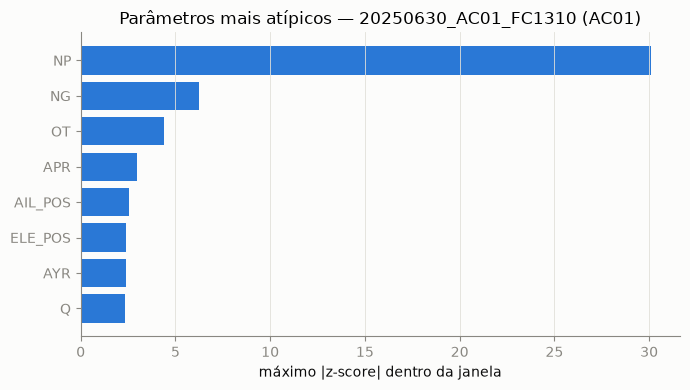

In [15]:
top8 = driver_table.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top8["parametro"], top8["max_abs_z"], color=BLUE)
ax.set_xlabel("máximo |z-score| dentro da janela")
ax.set_title(f"Parâmetros mais atípicos — {top['flight_id']} ({top['tail']})")
ax.grid(True, axis="x")
plt.tight_layout()
plt.show()

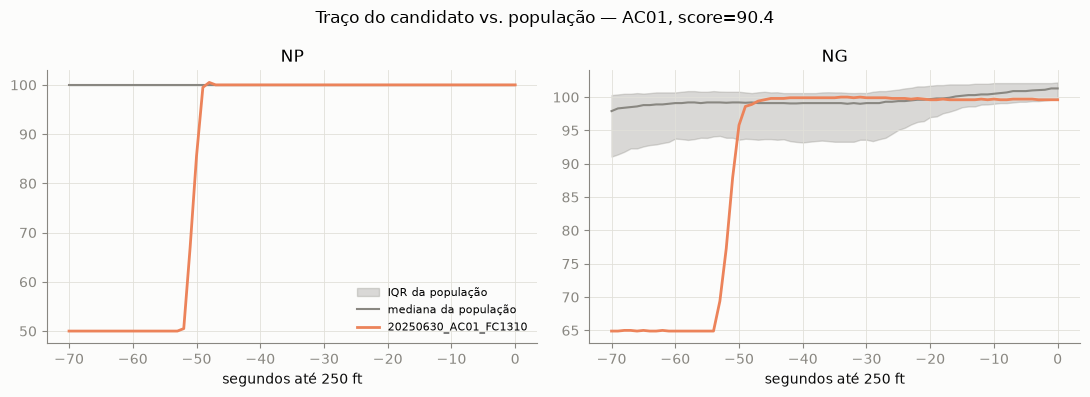

In [16]:
t_axis = np.arange(-WINDOW_Y_S, 1)
top2 = driver_table["parametro"].iloc[:2].tolist()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, p in zip(axes, top2):
    pi = FEATURE_ORDER.index(p)
    pop = raw_all[:, pi, :]
    med = np.median(pop, axis=0)
    q25, q75 = np.percentile(pop, [25, 75], axis=0)
    ax.fill_between(t_axis, q25, q75, color=GRAY, alpha=0.3, label="IQR da população")
    ax.plot(t_axis, med, color=GRAY, linewidth=1.5, label="mediana da população")
    ax.plot(t_axis, raw_candidate[pi], color=CANDIDATE, linewidth=2, label=top["flight_id"])
    ax.set_title(p)
    ax.set_xlabel("segundos até 250 ft")
    ax.grid(True)
axes[0].legend(frameon=False, loc="best", fontsize=8)
fig.suptitle(f"Traço do candidato vs. população — {top['tail']}, score={top['atypicality_kdist']:.1f}")
plt.tight_layout()
plt.show()

**Leitura**: os dois painéis mostram, em termos físicos e concretos, por que a
distância-K deste voo é a maior da população — muito além de dizer que "PC1 e PC2 estão
longe do centro". Este é exatamente o tipo de artefato interpretável que se leva para
uma conversa com manutenção: "o traço de `X` neste voo sai da faixa que os outros 927
ocupam, entre os segundos `A` e `B`". Uma extensão natural (fora deste notebook):
repetir o mesmo diagnóstico para AC03/AC06 especificamente, e ver se os *drivers* se
repetem entre os candidatos da mesma cauda — se sim, é mais um indício a favor de causa
comum por aeronave, a confirmar por registros de manutenção.

## 8. Limitações deste exercício

**Para quem está ouvindo, em uma frase**: nada neste notebook prova que algo deu errado
em algum voo específico — ele mostra apenas ONDE olhar primeiro, e por quê, deixando a
decisão final para quem entende de manutenção e operação da aeronave. As ressalvas
abaixo dizem até onde essa recomendação pode ir.

- **Uma população, um detector.** Só decolagem, só EMB 314, só a configuração literal
  PCA+DBSCAN. A comparação entre frotas e a grade de sensibilidade ficam fora daqui por
  uma decisão deliberada de recorte — cada uma continua sendo um complemento valioso
  para trabalho futuro, que reduziria ainda mais a chance de um achado ser artefato da
  configuração escolhida.
- **Sem rótulo de referência.** Nenhum voo aqui tem confirmação de pane ou de operação
  atípica. "Candidato" é apenas "extremo da distribuição sob esta configuração".
- **Corte binário é contingente; a ordenação é mais estável.** O alvo de ruído de 5% é
  uma escolha de conveniência pedagógica — uma calibração validada exigiria a bateria de
  robustez completa, fora deste recorte. Outra configuração razoável mudaria a lista
  exata de candidatos, mesmo que a ordem de atipicidade geral (a distância-K) tendesse a
  se manter parecida.
- **Colapso estrutural mantém o resultado válido.** DBSCAN formar poucos ou nenhum
  cluster além do principal é esperado dado $\rho$ e o cv da distância-K observados — os
  candidatos sinalizados continuam igualmente relevantes para revisão.
- **Concentração por aeronave (§6) tem caráter exploratório**: um ponto de partida para
  investigação. Poder estatístico baixo (16 candidatos / 8 caudas) e possível confusão
  entre aeronave, papel operacional/base **e configuração de carga** — tratar qualquer
  `p_holm` pequeno, ou qualquer leitura pós-carga-externa, como gatilho de investigação;
  o diagnóstico de problema estrutural cabe à revisão especializada seguinte. A mesma
  ressalva vale, com mais força ainda, para uma futura análise por piloto (dado hoje
  ausente).
- **A explicação local (§7) é um diagnóstico de desvio** — mais simples e mais direto do
  que uma atribuição formal. Ela aponta parâmetros com trajetória fora do padrão,
  oferecendo uma leitura física direta; a decomposição matemática exata da distância-K
  fica para trabalho futuro.

**Próximo passo natural** (fora deste notebook): confrontar esta leitura com registros
de manutenção do período coberto pelos 519 arquivos, quando disponíveis — a forma
correta de aproximar "candidato estatístico" de "achado com sustentação operacional".